In [2]:
from rdkit import Chem
import numpy as np
import csv
import sys
sys.path.append('molecule-web-app/backend/rules')  # replace with your local path
sys.path.append('molecule-web-app/backend')
# Now you can import your module as usual
from rules import execute_step
import helper
from ml_helper import make_fingerprint
from xgboost import XGBClassifier

In [3]:
all_data = []
with open('data/cc_ia.csv', newline='') as csvfile:
    reader = csv.reader(csvfile)
    for row in reader:
        all_data.append(row)

cc_rxns = np.array(all_data)[1 :,3]

In [34]:
clf = XGBClassifier()
clf.load_model('models/v13/xg_model.json')

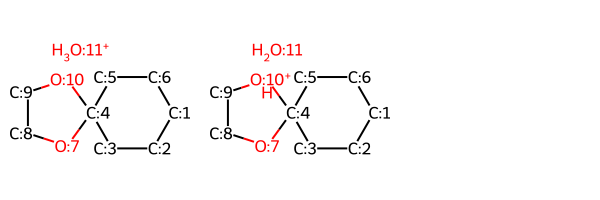

In [35]:
sm_list = []
prod_list = []
for rxn in cc_rxns:
    sm_list.append(Chem.MolFromSmiles(rxn.split('>>')[0]))
    prod_list.append(Chem.MolFromSmiles(rxn.split('>>')[1]))

idx = 90

sm = sm_list[idx]
prod = prod_list[idx]

Chem.SanitizeMol(sm)
Chem.SanitizeMol(prod)
Chem.Draw.MolsToGridImage([sm, prod])

In [36]:
sm_smiles = Chem.MolToSmiles(sm)
prod_smiles = Chem.MolToSmiles(prod)
output = execute_step(sm_smiles, True, True, None, False)
n_output = len(output[0])
smiles_list = []
success_list = []
for i in range(n_output):
    smiles = Chem.MolToSmiles(output[0][i])
    smiles_list.append(smiles)
    fp = make_fingerprint(output[0][i], output[1][i])
    pred = clf.predict(np.array(fp).reshape(1, -1))
    if pred[0] == 1:
        success_list.append(smiles)

if prod_smiles in smiles_list:
    print("Success")
if prod_smiles in success_list:
    print("Double success")

    

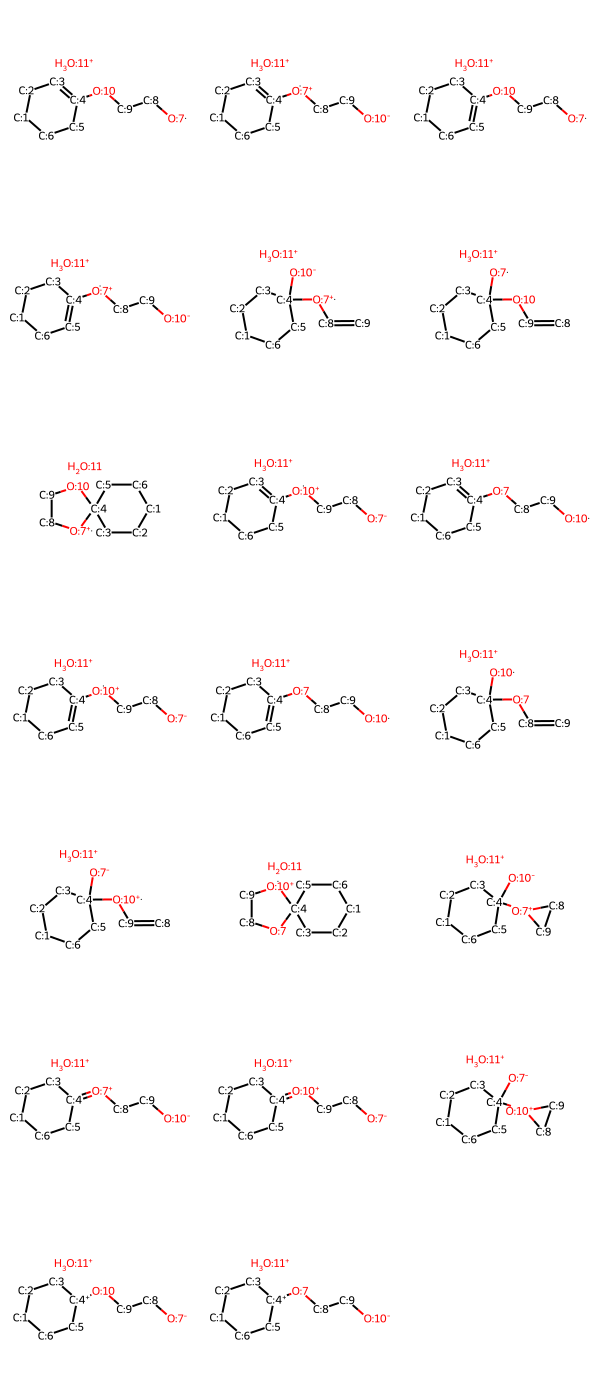

In [37]:
Chem.Draw.MolsToGridImage(output[0])

In [38]:
successes = []
low_successes = []
failures = []
for rxn in cc_rxns:
    sm = Chem.MolFromSmiles(rxn.split('>>')[0])
    prod = Chem.MolFromSmiles(rxn.split('>>')[1])
    for a in sm.GetAtoms():
        a.SetAtomMapNum(0)
    for a in prod.GetAtoms():
        a.SetAtomMapNum(0)
    Chem.RemoveStereochemistry(sm)
    Chem.RemoveStereochemistry(prod)
    prod_smiles = Chem.MolToSmiles(prod)
    sm_smiles = Chem.MolToSmiles(sm)
    prod_smiles = Chem.MolToSmiles(prod)
    print(sm_smiles)
    output = execute_step(sm_smiles, True, True, None, False)
    n_output = len(output[0])
    smiles_list = []
    success_list = []
    for i in range(n_output):
        Chem.SanitizeMol(output[0][i])
        smiles = Chem.MolToSmiles(output[0][i])
        smiles_list.append(smiles)
        fp = make_fingerprint(output[2], output[1][i])
        pred = clf.predict(np.array(fp).reshape(1, -1))
        if pred[0] == 1:
            success_list.append(smiles)

    if prod_smiles in smiles_list:
        low_successes.append(rxn)
    else:
        failures.append(rxn)
    if prod_smiles in success_list:
        successes.append(rxn)
    

CC(C)([O-])C#N.[OH3+]
CC(=O)C(C)C.[BH4-]
CCCCC(C)[O-].Cl
CC(=O)c1ccccc1.O
CC([O-])([OH2+])c1ccccc1
CC([O-])([OH2+])c1ccccc1
CCC(C)=[OH+].CCO
CCC(C)=[OH+].CCO
CC[O-].O=Cc1ccccc1
COC(C)(C)[OH2+]
COC(C)(C)[OH2+]
CO.C[O+]=C(C)C
CC(=O)Cl.CC[O-]
CCOC(C)([O-])Cl
CC(C)[N-]C(C)C.CCC(C)=O
CC(C)[N-]C(C)C.CCC(C)=O
CCCC[N+](=O)[O-].CC[O-]
CC(C)(C)[O-].CCC(=O)CC(C)=O
CC(C)(C)[O-].CCC(=O)CC(C)=O
CC(C)(C)[O-].CCC(=O)CC(C)=O
CC(C)(C)[O-].CCC(=O)CC(C)=O
COC(N)([O-])c1ccccc1
CCC[OH2+].[Br-]
CCC[OH2+].[Br-]
CC([O-])=CC(O)c1cccc(C)c1
C=C(C)CCC=O.[C-]#N
C[O+]=C1C=C2CCCCC2CC1.C[O-]
C[O+]=C1C=C2CCCCC2CC1.C[O-]
C=C(C)[O-].O=Cc1ccccc1
C=CC(C)=O.CC[O-]
C=CC(C)=O.CC[O-]
CC(=O)c1ccccc1.[BH3-]OC(C)C
CC(=O)CC(O)c1ccccc1.[OH-]
CC(=O)CC(O)c1ccccc1.[OH-]
CC(=O)O.CNC
CC1(O)CCCCC1.[OH3+]
CC1([OH2+])CCCCC1
CCC(F)Br.[OH-]
CCOCCl
C[O-].O=C(CCl)c1ccccc1
C[O-].O=C(CCl)c1ccccc1
C[O-].O=C(CCl)c1ccccc1
CC[S+](Cc1ccccc1)Cc1ccccc1.[C-]#N
Cc1ccc(S(=O)(=O)Cl)cc1.OCC1C=CCC1
C[OH+]c1ccccc1.[I-]
C[OH+]c1ccccc1.[I-]
CC1CO1.CCNC
B.CCC=C(

In [39]:
len(successes)

117

In [40]:
len(low_successes)

133

In [11]:
len(failures)

14

In [12]:
len(cc_rxns)

147

In [13]:
unpredicted = []
for rxn in low_successes:
    if rxn not in successes:
        unpredicted.append(rxn)

In [48]:
accounted_for = 0
unaccounted_for = []
unaccounted_for_prod =[]
for idx in range(len(failures)):
    smiles = str(failures[idx]).split('>>')
    sm = Chem.MolFromSmiles(smiles[0])
    for a in sm.GetAtoms():
        a.SetAtomMapNum(0)
    sm_smiles = Chem.MolToSmiles(sm)
    prod = Chem.MolFromSmiles(smiles[1])
    for a in prod.GetAtoms():
        a.SetAtomMapNum(0)
    Chem.RemoveStereochemistry(prod)
    prod_smiles = Chem.MolToSmiles(prod)
    output = execute_step(sm_smiles, True, True, None, False)
    n_output = len(output[0])
    smiles_list = []
    found = False
    for i in range(n_output):
        Chem.SanitizeMol(output[0][i])
        if output[0][i].HasSubstructMatch(keto_enol) or output[0][i].HasSubstructMatch(double_bond) or output[0][i].HasSubstructMatch(hydroboration):
            accounted_for += 1
            found = True
            break
        smiles_out = Chem.MolToSmiles(output[0][i])
        smiles_list.append(smiles_out)
        #fp = make_fingerprint(output[0][i], output[1][i])
        #pred = clf.predict(np.array(fp).reshape(1, -1))
    if not found:
        unaccounted_for.append(sm)
        unaccounted_for_prod.append(prod)
print(accounted_for)
#print(smiles_list[9])
#Chem.Draw.MolsToGridImage([sm, prod]+   output[0])

13


In [15]:
unaccounted_for[0]

IndexError: list index out of range

In [16]:
Chem.MolToSmiles(unaccounted_for_prod[0])

IndexError: list index out of range

SMARTS matching to deal with annoying cases

In [45]:
keto_enol = Chem.MolFromSmarts('[O,N,S;!-]=[*][C-]')
double_bond = Chem.MolFromSmarts('[C+][*-]')
hydroboration = Chem.MolFromSmarts('[C+]C[B-]')

In [46]:
for failure in failures:
    sm = Chem.MolFromSmiles(failure.split('>>')[0])
    prod = Chem.MolFromSmiles(failure.split('>>')[1])
    if sm.HasSubstructMatch(keto_enol) or sm.HasSubstructMatch(double_bond) or sm.HasSubstructMatch(hydroboration):
        print(failure)
        print(sm.HasSubstructMatch(keto_enol))
        print(sm.HasSubstructMatch(double_bond))
        print(sm.HasSubstructMatch(hydroboration))
        print("")


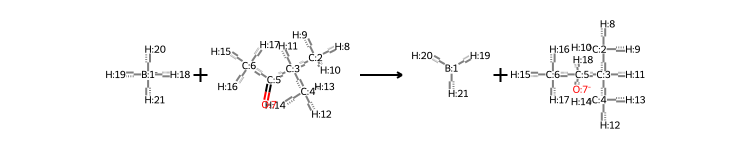

In [47]:
Chem.rdChemReactions.ReactionFromSmarts(cc_rxns[1])

In [20]:
cc_rxns[1]

np.str_('[B-:1]([H:18])([H:19])([H:20])[H:21].[C:2]([C:3]([C:4]([H:12])([H:13])[H:14])([C:5]([C:6]([H:15])([H:16])[H:17])=[O:7])[H:11])([H:8])([H:9])[H:10]>>[B:1]([H:19])([H:20])[H:21].[C:2]([C:3]([C:4]([H:12])([H:13])[H:14])([C:5]([C:6]([H:15])([H:16])[H:17])([O-:7])[H:18])[H:11])([H:8])([H:9])[H:10]')

[0]


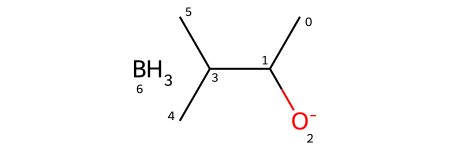

In [35]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True
print(pred)
output[0][2]


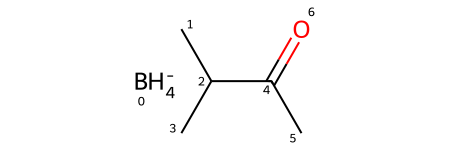

In [36]:
sm

In [21]:
output[1]

[[8, 2, 0, 1, 2], [8, 2, 3, 1, 2], [7, 6, 1, None, 2]]

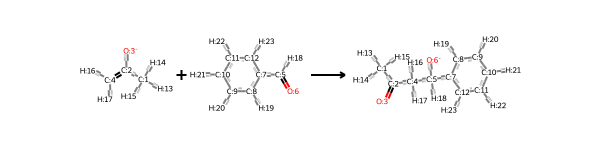

In [44]:
Chem.rdChemReactions.ReactionFromSmarts(failures[2])